In [1]:
# Generelle moduler og funksjonsbeskrivelser brukt i forelesningen
from numpy import sin, cos, pi, exp
import scipy.signal as sig
import numpy.fft as fft
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = [8.00, 4.5]
plt.rcParams["figure.autolayout"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.xmargin"] = 0.0



<img src="figures/NTNU_logo_vertical.svg" align="left" style="width: 30%">
<br clear="all" />
<br></br>

# Basic Digital Filters

* **Course AIS2201 - Signalbehandling**
* **Week 41, 2025**
* **Lecturer: Kai Erik Hoff**


# Topics

* Difference filter
    * Difference equation and block diagram
    * Step response
    * Application 1: edge detection
    * Application 2: differentiation
* Moving average filter
    * Difference equation and block diagram
    * Step response
    * Application: signal smoothing
    * Recursive form
* Exponential averager
    * Difference equation and block diagram
    * Step response and RC circuit comparison
    * Application 1: signal smoothing
    * Application 2: DC removal
    * Application 3: smoothed differentiation
    * Application 4: real-time signal analyzer

# Discrete-time Causal LTI-systems:

* Described using a ***difference equation***
$$\Large \sum_{k=0}^{M} a_k \cdot y[n-k] = \sum_{k=0}^{N} b_k \cdot x[n-k]$$
    * The series $a_k$ and $b_k$ are known as *filter coefficients*

# First order difference filter


<div style="width:90%">
<img src="figures/simple_difference.svg" style="float:right; width:40%"/>
<br>
<ul>
    <li>Difference Equation:</li>
</ul>
$$\Large y[n] = x[n] - x[n-1]$$     
</div>

In [2]:
def diff_filt(x: np.ndarray) -> np.ndarray:
    y = np.zeros(len(x))
    y[0] = x[0]
    for n in range(1, len(x)):
        y[n] = x[n] - x[n-1]
    return y

## Response to change in input level

Text(0.5, 0, 'Sample number $n$')

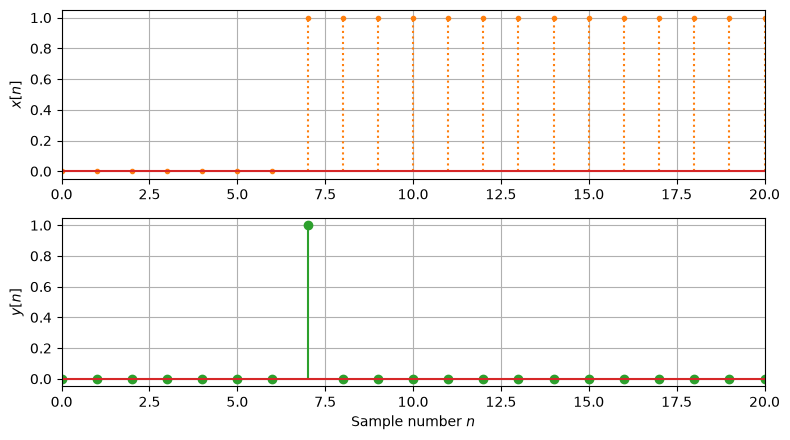

In [3]:
n = np.arange(21)
x = np.heaviside(n-7, 1)  # Input is a step functionb
y = diff_filt(x)
plt.close(1); plt.figure(1)
plt.subplot(2,1,1)
plt.stem(x, markerfmt=".", linefmt="C1:", label="$x[n]$")
plt.ylabel("$x[n]$")
plt.subplot(2,1,2)
plt.stem(y, markerfmt="o", linefmt="C2", label="$y[n]$")
plt.ylabel("$y[n]$")
plt.xlabel("Sample number $n$")

#### Notes:

The current output $y[n]$ being equal to the difference between the most recent input sample $x[n]$ and the previous input sample $x[n-1]$, the filter will produce a nonzero output whenever the level of the input signal $x[n]$ changes. 

## Application: edge detection

# Accumulator


<div style="width:90%">
<img src="figures/accumulator.svg" style="float:right; width:50%"/>
<br>
<ul>
    <li>Difference Equation:</li>
</ul>
$$\Large y[n] = x[n] + y[n-1]$$     
</div>

In [4]:
def accumulator(x: np.ndarray) -> np.ndarray:
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n] = x[n] + y[n-1]
    return y

## Response to change in input 

Text(0.5, 0, 'Sample number $n$')

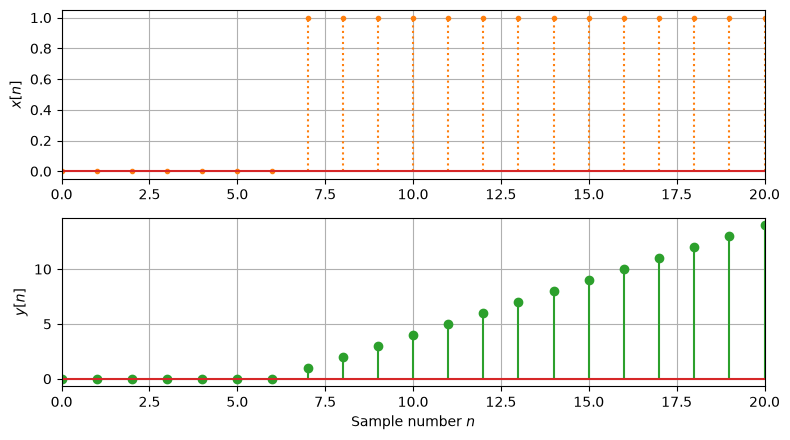

In [5]:
n = np.arange(21)
x = np.heaviside(n-7, 1)  # Input is a step function
y = accumulator(x)

# Plot code
plt.close(1); plt.figure(1)
plt.subplot(2,1,1)
plt.stem(x, markerfmt=".", linefmt="C1:")
plt.ylabel("$x[n]$")
plt.subplot(2,1,2)
plt.stem(y, markerfmt="o", linefmt="C2")
plt.ylabel("$y[n]$")
plt.xlabel("Sample number $n$")

## Application: PID Control

* Both the first order differentiator and the accumulator are filters you probably already have used when implementing PID controllers.

<img src="figures/PID_controller.svg" style="width: 60%; margin-left: 200px" />

# Moving Average Filter

* Block Diagram:
<img src="figures/moving_average.svg" style="width: 80%; margin-left: 100px" />

* Difference Equation:
$$\Large y[n] = \frac{1}{N}\sum_{k=0}^{N-1}x[n]$$     

* Python Implementation:

In [6]:
def moving_average(x, N):
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n]= x[n]
        for k in range(1, N):
            y[n] += x[n-k] if n-k>=0 else 0
        y[n] /= N
    return y

## Response to change in input level

Text(0.5, 0, 'Sample number $n$')

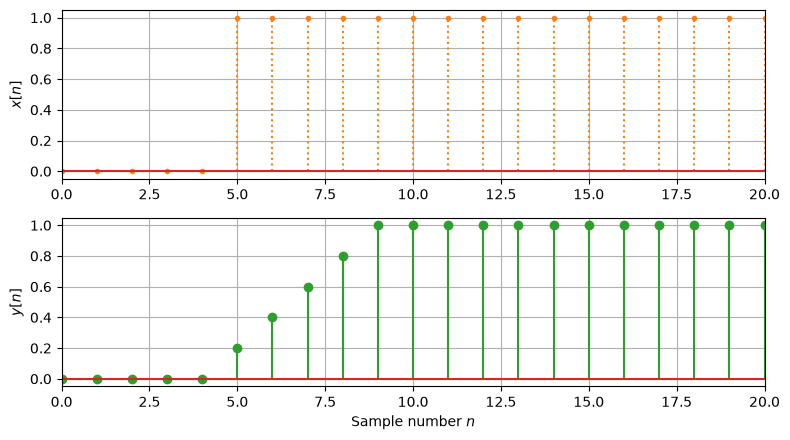

In [7]:
n = np.arange(21)
x = np.heaviside(n-5, 1)  # Input is a step function
y = moving_average(x, 5)

# Plot code
plt.close(1); plt.figure(1)
plt.subplot(2,1,1)
plt.stem(x, markerfmt=".", linefmt="C1:")
plt.ylabel("$x[n]$")
plt.subplot(2,1,2)
plt.stem(y, markerfmt="o", linefmt="C2")
plt.ylabel("$y[n]$")
plt.xlabel("Sample number $n$")

## Application: *signal smoothing*

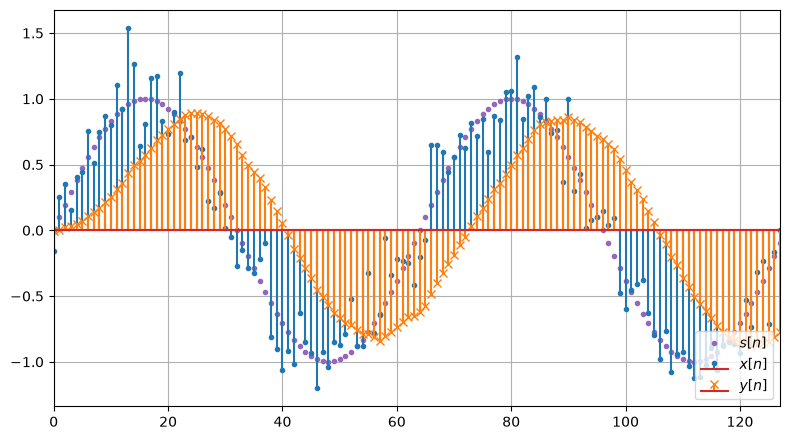

In [27]:
# Create noisy signal
n = np.arange(128)
s = sin(2*pi*n/64)
x = s + np.random.randn(len(n))*.2

# Perform smoothing (apply @interact?)
y = moving_average(x, 20)

# Plot signals
plt.figure()
plt.plot(n, s, '.C4', label="$s[n]$")
plt.stem(n, x, markerfmt='.', label="$x[n]$")
plt.stem(n, y, markerfmt="x", linefmt="C1", label="$y[n]$")
plt.legend(loc="lower right")

#### Notes: 
While simple, the moving average filter is widely used. Statistically, in a scenario where we take $N$ noisy measurements of some constant quantity $c$, averaging those $N$ samples is the ***optimal*** estimator for $c$. 

In the case of smoothing a signal $x[n]$ , we see that the moving average filter works quite well, but introduces a certain delay to the output waveform. In addition, we also see that the output waveform $y[n]$ is mildy attenuated in comparison to $s[n]$. This is due to the frequency response properties of the moving average filter, which we will discuss latoer on.

## Alternate form: *recursive*

* Block Diagram:
<img src="figures/moving_average_recursive.svg" style="width: 80%; margin-left: 100px" />

* Difference equation:
$$\Large y[n] = y[n-1] + \frac{1}{N}\left(x[n] - x[n-N]\right)$$

* Example Python function

In [12]:
def moving_average_recursive(x, N):
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n] = y[n-1] + (x[n] - (x[n-N] if n-N>0 else 0))/N
    return y

#### Notes:
The recursive moving average filter is a neat little bit of code optimization, as the output is calculated using one multiplication, one addition and one subtraction *no matter how large $N$ is*. The filter still requires storing $N$ samples in memory however.

Text(0.5, 0, 'Sample number $n$')

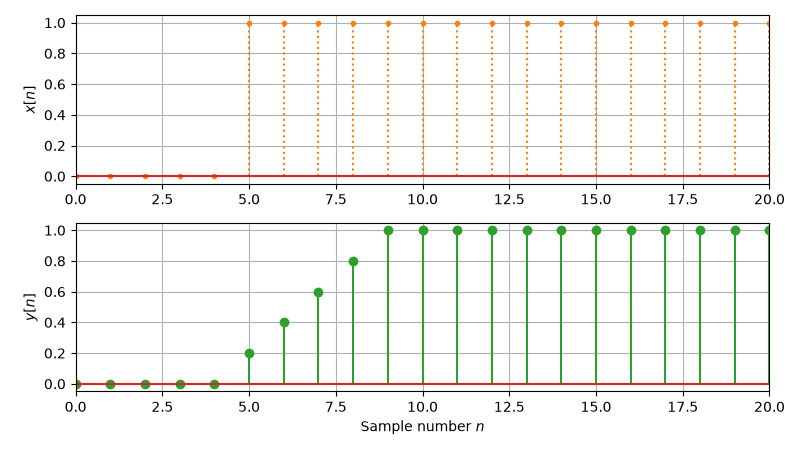

In [13]:
n = np.arange(21)
x = np.heaviside(n-5, 1)  # Input is a step function
y = moving_average_recursive(x, 5)

# Plot code
plt.close(1); plt.figure(1)
plt.subplot(2,1,1)
plt.stem(x, markerfmt=".", linefmt="C1:")
plt.ylabel("$x[n]$")
plt.subplot(2,1,2)
plt.stem(y, markerfmt="o", linefmt="C2")
plt.ylabel("$y[n]$")
plt.xlabel("Sample number $n$")

# Exponential averager

* Block Diagram:
<img src="figures/exponential_averager.svg" style="width: 80%; margin-left: 100px" />

* Difference Equation:
$$\Large y[n] = \alpha \cdot x[n] + (1-\alpha)\cdot y[n-1]$$     

* Example python function:

In [29]:
def exponential_average(x, alpha=0.1):
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n] = alpha*x[n] + (1-alpha)*y[n-1]
    return y

#### Notes:
Widely used filter, which is elegantly simple as well as practical. Depending on the literature source, exponential averagers may sometimes be referred to simply as a "digital lowpass filter".

## Response to change in input level

Text(0.5, 0, 'Sample number $n$')

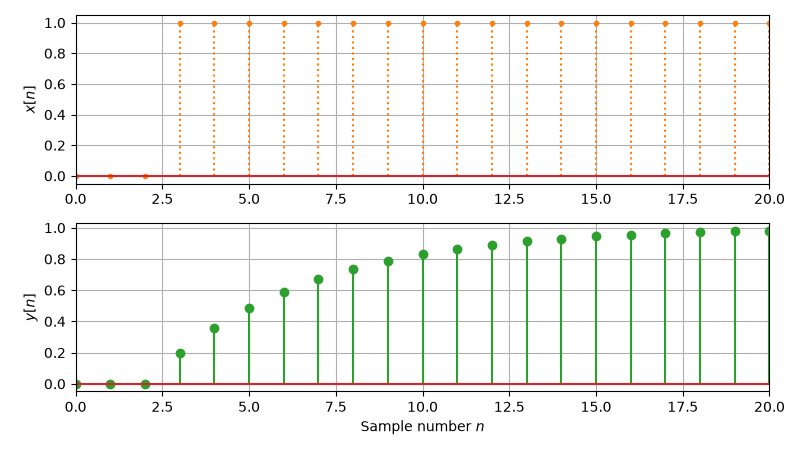

In [27]:
n = np.arange(21)
x = np.heaviside(n-3, 1)  # Input is a step function
y = exponential_average(x, 0.2)

# Plot code
plt.close(1); plt.figure(1)
plt.subplot(2,1,1)
plt.stem(x, markerfmt=".", linefmt="C1:")
plt.ylabel("$x[n]$")
plt.subplot(2,1,2)
plt.stem(y, markerfmt="o", linefmt="C2")
plt.ylabel("$y[n]$")
plt.xlabel("Sample number $n$")

## Comparison with RC-circuit

$$\large x[n] = \begin{cases}0,& x\leq0 \\ 1,& x>1 \end{cases}$$
$$\large y[n] = 1 - (1-\alpha)^{n} = 1 - e^{-\frac{n}{\ln(1-\alpha)}}$$

## Application 1: *signal smoothing*

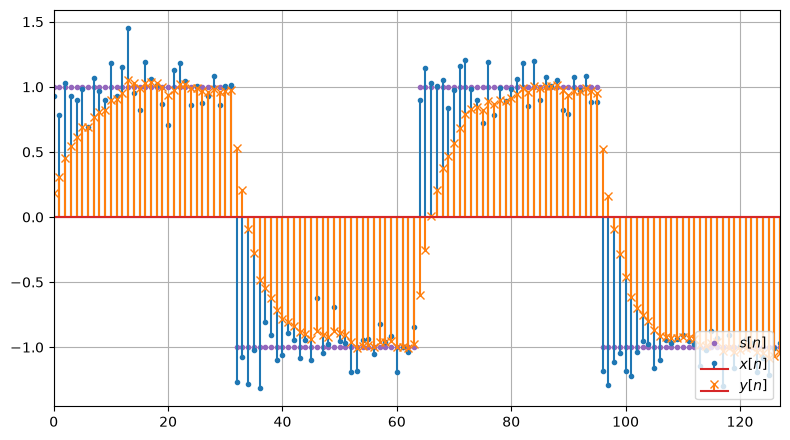

In [34]:
# Create noisy signal
n = np.arange(128)
s = sig.square(2*pi*n/64)
x = s + np.random.randn(len(n))*.15

# Perform smoothing (apply @interact?)
y = exponential_average(x, alpha=0.2)

# Plot signals
plt.figure()
plt.plot(n, s, '.C4', label="$s[n]$")
plt.stem(n, x, markerfmt='.', label="$x[n]$")
plt.stem(n, y, markerfmt="x", linefmt="C1", label="$y[n]$")
plt.legend(loc="lower right")

## Application 2: *DC removal*

## Application 3: *lowpass differentiation*


## Applicatoin 4: *sensor fusion*

## Application 5: *real-time spectral analyzer*

# Digital filter properties: *The Impulse Response*

<img src="figures/impulse_response.svg" style="width: 60%; margin-left: 200px" />

* The mathematical properties of a digital filter which is both linear and time-invariant are contained entirely within it's impulse response.

<!--
* Premiss for LTI-system:
    * *Dersom systemets reaksjon til en deltapuls $\delta[n]$ er kjent, er det mulig å predikere hvordan systemet vil reagere på alle mulige inngangssignal.*
* Utgangssignalet til et LTI-system gitt en impuls $\delta[n]$ som inngangssignal kalles impulsresponsen $h[n]$ til systemet.
-->

# *Recap: the discrete delta pulse*

<img src="figures/Fig1_dn.svg" style="width: 40%; margin-left: 10%; margin-right:10%" align="right"/>

* **Definiton:**

$$
\Large
\delta[n] = 
\begin{cases}
1, n=0\\
0, n\neq 0
\end{cases}
$$


# Filter categories

### **I**nfinite **I**mpulse **R**esponse (IIR)
* Uses previous values of both input $x[n-k]$ and output $y[n-k]$ as basis for calculating the updated output value $y[n]$.
* General algorithm for IIR filters:

$$\Large y[n] = \frac{1}{a_0}\cdot \left(\sum_{k=0}^{N} b_k \cdot x[n-k] - \sum_{k=1}^{M}a_k\cdot  y[n-k] \right)$$

### **F**inite **I**mpulse **R**esponse (FIR)
* Uses *only* previous input values $x[n-k]$ as a basis for calculating
* General algorithm for FIR filtrs:
$$\Large y[n] = \sum_{k=0}^{N} b_k \cdot x[n-k]$$

# IIR filter system diagram

<img src="figures/df1.svg" style="margin-left:25%;width:50%"/>

* Filter order: $\max(M, N)$
    * *How many samples into the past does the IIR filter need to "remember"*

## Example of a IIR filter: *exponential averager*

* The output is a weighted sum of the current input $x[n]$ and the previous output $y[n-1]$:
$$y[n] = \alpha \cdot x[n] + (1-\alpha) \cdot y[n-1]$$

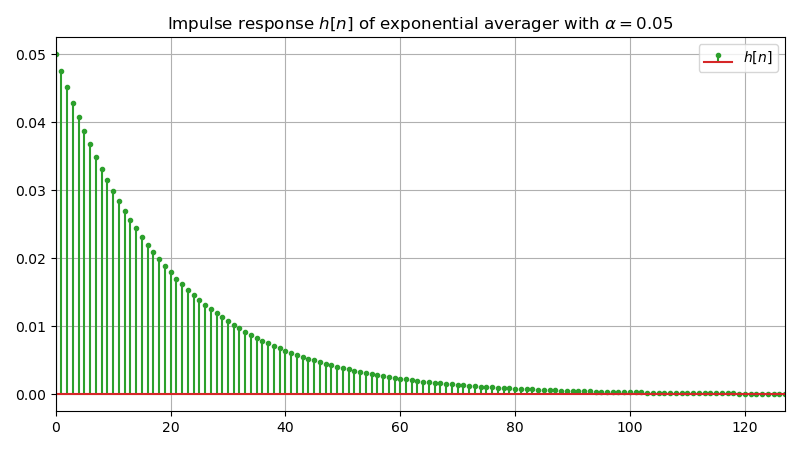

In [2]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt 
def exponential_averaging(x: np.ndarray, alpha=0.1):
    """
    Function to perform exponential averaging on an input signal 'x'. 
    Filtering function: y[n] = alpha*x[n] + (1-alpha)*y[n-1]

    Parameters:
    - x: Array representing input signal
    - alpha: Smoothing factor 0 < alpha < 1

    Returns:
    - y: Array containing filtered output
    """
    L = len(x)  # length of signal
    y = np.zeros(L)
    for n in range(L):
        y[n] = alpha*x[n] + (1-alpha)*y[n-1]
    return y


N = 128
dn = np.zeros(N)
dn[0] = 1
hn = exponential_averaging(dn, alpha=0.05)

plt.close(1); plt.figure(1)
plt.title("Impulse response $h[n]$ of exponential averager with $\\alpha=0.05$")
plt.stem(hn, markerfmt=".", linefmt="C2", label="$h[n]$")
plt.legend(loc="upper right")

* Categorized as an IIR filter because $h[n]$ will never be *precisely* equal to $0$ for any $n\geq0$

# Designing IIR filters *(as covered in AIS2102 discretization module)*

1. Determine desired filter response properties (filter order, lowpass/highpass, cutoff frequency etc...)

In [3]:
f_c = 100 # Cutoff frequency (Hz)
filter_type = "lowpass"
filter_order = 4

2. Design an *analog* filter ([butterworth](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html#scipy.signal.butter), [chebyshev](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.cheby1.html#scipy.signal.cheby1), [bessel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.bessel.html#scipy.signal.bessel) etc...) with the desired response

Text(0, 0.5, 'Filter gain (dB)')

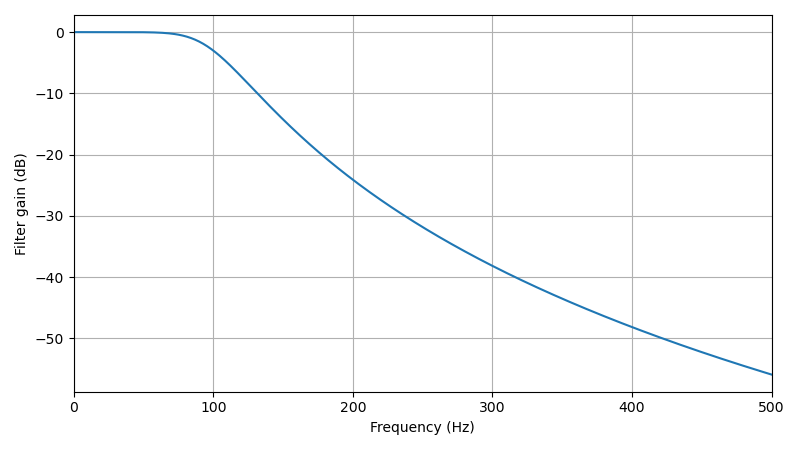

In [4]:
b, a = sig.butter(filter_order, f_c*2*np.pi, filter_type, analog=True)
w, Hw = sig.freqs(b, a, worN=np.pi*2*np.linspace(0, 500, 513))
plt.close(2); plt.figure(2)
plt.plot(w/2/np.pi, 20*np.log10(np.abs(Hw)))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter gain (dB)")

3. *Discretize* the analog filter, typically using Tustin's method (aka. Bilinear Transform aka. trapezoidal integration) with pre-warping.
    * *Tustin's method is preferred for DSP applications because it allows us to retain corner frequencies precisely*

(-100.0, 12.005490632705648)

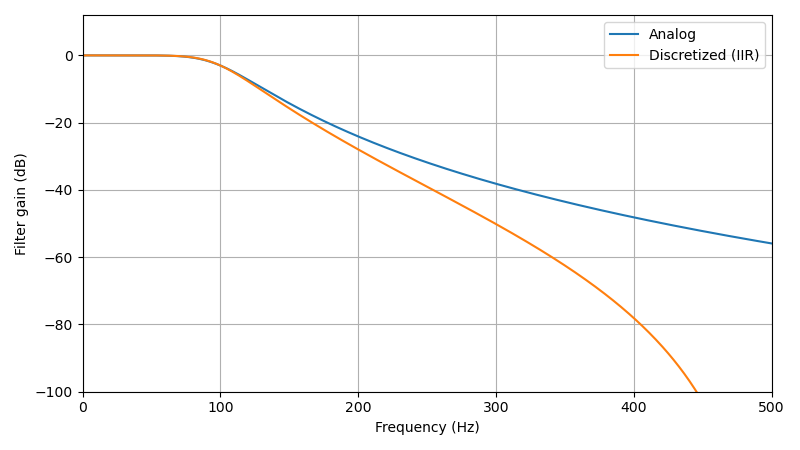

In [5]:
fs = 1_000 # samples / second
fs_warped = (np.pi*f_c)/np.tan(np.pi*f_c/fs)  # Perform pre-warping of cutoff frequency
b_d, a_d = sig.bilinear(b, a, fs=fs_warped)   # Discretize using trapezoidal integration
f_d, Hf_d = sig.freqz(b_d, a_d, fs=fs)

plt.close(3); plt.figure(3)
plt.plot(w/2/np.pi, 20*np.log10(np.abs(Hw)), label="Analog")
plt.plot(f_d, 20*np.log10(np.abs(Hf_d)), label="Discretized (IIR)")
plt.legend()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter gain (dB)"); plt.ylim(ymin=-100)

## Signal filtering using `scipy`:

* General function for filtering with LTI-systems: [`scipy.signal.lfilter(b, a, x)`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html).
* Function Parameters:
    * `b`: Filter coefficients $b_k$
    * `a`: Filter coefficients $a_k$
    * `x`: Array containing input signal $x[n]$ to be filtered.


(0.0, 127.0)

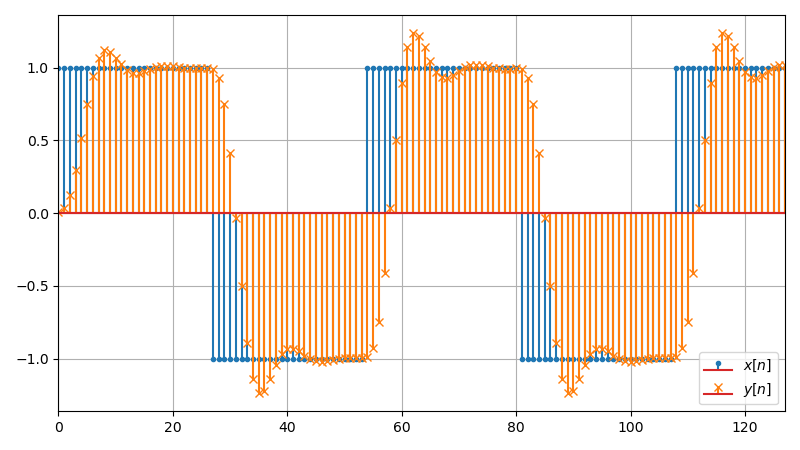

In [6]:
# Example using discretized filter from perevious slide
import scipy.signal as sig

# Generate input square wave signal
N = 128
n = np.arange(N)
xn = sig.square(np.pi/27*n)

# Perform filtering
yn = sig.lfilter(b_d, a_d, xn)

# Display input and output signal
plt.figure()
plt.stem(xn, markerfmt='.', label="$x[n]$")
plt.stem(yn, markerfmt="x", linefmt="C1", label="$y[n]$")
plt.legend(loc="lower right")
plt.xlim([0, N-1])

Mathematically, an IIR filter is identical to a discrete controller or a discretized system model. The only difference is mathematical notation, and the domain of application (the discrete controller is inserted into a closed loop, while the terminology "IIR filter" typically refers to a stand-alone "open-loop" system for filtering e.g. music).

Since the theory behind IIR filters and discrete control theory is the same, IIR filters will not play a major role in this course's curriculum. If you wish a refresher, chapter 6 covers this topic in detail.

# What is a FIR filter?


 


* **FIR** - **F**inite **I**mpulse **R**esponse

* Describes a digital filter which calculates the output $y[n]$ based *only* on a linear combination of the input values $x[n]$ at various samplingtimes.

* Entirely described by the filter coefficients $b_k$

* Can be viewed as a Discrete LTI-system where $a_k$ equals:
$$
a_k = 
\begin{cases}
1,\ \ \  k = 0\\
0,\ \ \  k \neq 0
\end{cases}
$$

* Difference equation for FIR filters:
### $$ y[n] = \sum_{k=0}^{N} b_k \cdot x[n-k]$$

* $N$ denotes the *filter order*
    * Determines how many samples "back in time" the FIR filter needs to keep samples in the buffer.

* Mathematically much simpler to work with than a IIR filter

# FIR filter system diagram


<br>
<img src="figures/tapped_delay_line.svg" style="width: 60%; margin-left: 10%" />




* FIR filters commonly referred to as *tapped delay line* filters

* Number of "taps" ($M=N+1$) are a more common metric for size of filter than the filter order

## Example of a FIR filter: *moving average filter*
* The output $y[n]$ is the ***mean*** of the $M$ most recent input values $x[n-k], k \in \{0, 1, \ldots , M-1\}$.

$$y[n] = \frac{1}{M} \sum_{k=0}^{M-1} x[n-k]$$



(0.0, 127.0)

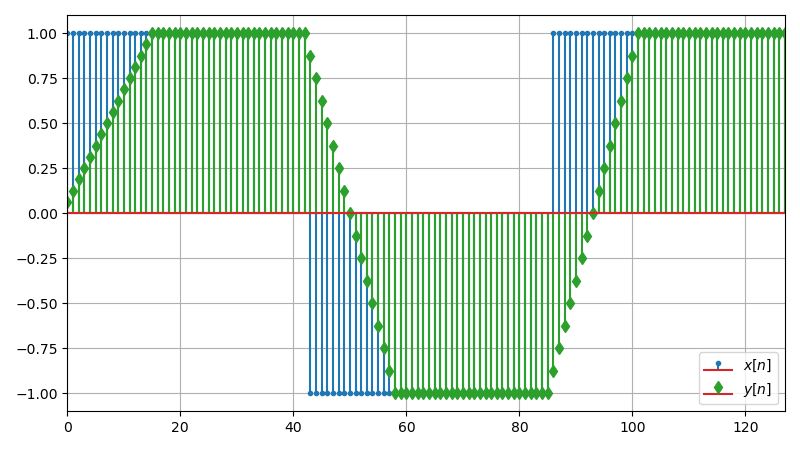

In [10]:
def moving_average(x: np.ndarray, M=16):
    """
    Function to perform moving average filtering of an input signal 'x'.
    Filtering function: y[n] = (x[n] + x[n-1] + ... + x[n-K+1])/K

    Parameters:
    - x: Array representing input signal
    - K: Length of averaging "window"

    Returns:
    - y: Array containing filtered output
    """
    L = len(x)
    y = np.zeros(L)
    for n in range(L):
        y[n] = np.sum(x[n:max(n-M,0):-1])/M
    return y


N = 128
n = np.arange(N)
xn = sig.square(2*np.pi*1.5*n/N)
#yn = moving_average(xn, M=16)
yn = sig.lfilter(np.ones(16)/16, [1], xn)

plt.figure()
plt.stem(xn, markerfmt='.', label="$x[n]$")
plt.stem(yn, markerfmt="d", linefmt="C2", label="$y[n]$")
plt.legend(loc="lower right")
plt.xlim([0, N-1])

## Quiz-question:

* What are the filter coefficients $b_k$ of a $M=8$-tap moving average filter?

# Let's return to our mystery equation:

$$y[n] = \frac{1}{16} \cdot x[n] + \frac{1}{4} \cdot x[n-2] + \frac{3}{8} \cdot x[n-4] + \frac{1}{4} \cdot x[n-6] + \frac{1}{16} \cdot x[n-8] \tag{1}$$

* Code to process signal according to equation $1$:

In [13]:
def filter_signal(x):
    y= []
    for n in range(len(x)):
        yn = 1/16*x[n]
        for k, bk in zip([2, 4, 6, 8], [1/4, 3/8, 1/4, 1/16]):
            if n - k >= 0:
                yn += x[n-k]*bk
        y.append(yn)
    return y

* "Manual" analysis of filter:

interactive(children=(IntSlider(value=2, description='f', max=50, min=2, step=2), Output()), _dom_classes=('wi…

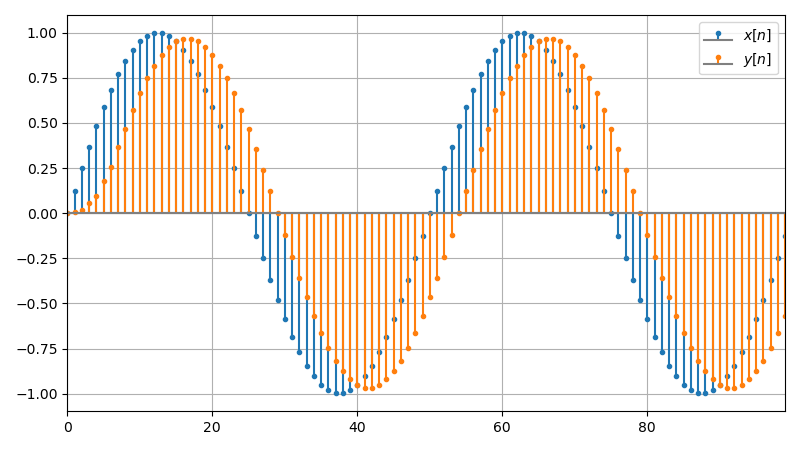

In [15]:
from ipywidgets import interact, IntSlider
fs = 100
plt.subplots(1,1)
@interact(f = IntSlider(min=2, max=50, step=2, value=2))
def display_xn_yn(f):
    w = 2*np.pi*f/fs
    n = np.arange(fs)
    xn = np.sin(w*n)
    yn = filter_signal(xn)
    plt.cla()
    plt.stem(n, xn, basefmt="grey", linefmt="C0", markerfmt=".C0", label="$x[n]$")
    plt.stem(n, yn, basefmt="grey", linefmt="C1", markerfmt=".C1", label="$y[n]$")
    plt.legend()

# Questions?